Math explained in Archive folder

In [108]:
import os
from pathlib import Path
from dotenv import load_dotenv

import matplotlib.pyplot as plt
from matplotlib.offsetbox import OffsetImage, AnnotationBbox
import numpy as np
import pandas as pd 
load_dotenv(override=True);
from matplotlib.pyplot import gca

In [100]:
data_repo_env = os.getenv("DATA_REPO_PATH")
DATA_REPO_DIR = Path(data_repo_env)

shotscsv = DATA_REPO_DIR / "GW7" / "shots.csv"
playerscsv = DATA_REPO_DIR / "GW7" / "players.csv"

shots = pd.read_csv(shotscsv)
players = pd.read_csv(playerscsv)


In [96]:
left_post = 55.4
right_post = 44.6
crossbar_height = 100/3

In [101]:
img = plt.imread('soccer-ball.png') 

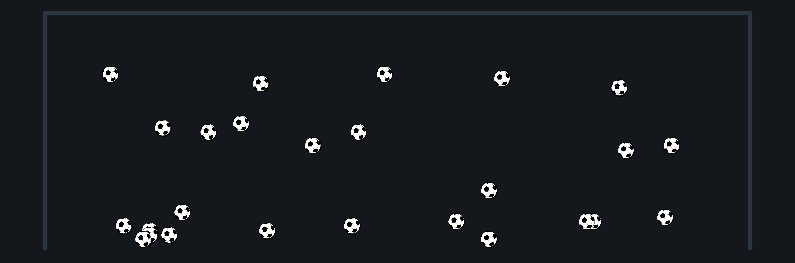

In [117]:
shots["goal_mouth_y_rel"] = ((left_post - shots["goal_mouth_y"])/(left_post - right_post)) * 100
shots["goal_mouth_z_rel"] = shots["goal_mouth_z"]

#(shots["goal_mouth_z"] / 100) * crossbar_height

fig, ax = plt.subplots(figsize = (10, 5))

x_coords = [0, 0, 100, 100]
y_coords = [0, crossbar_height, crossbar_height, 0]

# 1. Draw Goal Frame (white line for dark background)
ax.plot(x_coords, y_coords, color='#2C3440', lw=3)

shots_player_goal = shots[(shots["outcome"] == "goal")]
#shots_player_save = shots[(shots["outcome"] == "save")]

for xi, yi in zip(shots_player_goal["goal_mouth_y_rel"], shots_player_goal["goal_mouth_z_rel"]):
    imagebox = OffsetImage(img, zoom=0.15) 

    # Position the image box at the data coordinates (xi, yi)
    ab = AnnotationBbox(imagebox, (xi, yi), frameon=False)
    
    # Add it to the plot axis
    ax.add_artist(ab)

ax.scatter( 
    shots_player_goal["goal_mouth_y_rel"],
    shots_player_goal["goal_mouth_z_rel"],
    color="white",
    edgecolors="black",
    s=120
)
# ax.scatter( 
#     shots_player_save["goal_mouth_y_rel"],
#     shots_player_save["goal_mouth_z_rel"],
#     color="red",
#     edgecolors="black",
#     s=120
# )
ax.set_xlim(-5, 105)
ax.set_ylim(-0.2, crossbar_height + 0.5)

fig.patch.set_facecolor('#14181C')
ax.set_aspect('equal')
plt.xticks([])
plt.yticks([])
plt.axis('off')
plt.show()